# Grant · Single-subject insula high-gamma responses

This notebook contains **D0153 · Lexical Delay** (sections 1–4) and **D0149 / D149 · Picture Naming · RTAS5–6** (sections 5–8). Each subject has its own audit and three-phase figures.

## D0153 · Lexical Delay

Temporary grant summary; separate from `grant_nmf_30subjects.ipynb` in this directory.

Run all cells in the existing **ieeg** environment on Slurm. This notebook first audits upstream files and existing significance results, then plots all completed conditions (Decision and Repeat), without re-running preprocessing or statistical testing.

**Scope:** three panels, Stimulus (−0.5 to 0.6 s), Delay (0 to 1 s), Response (−0.5 to 1.5 s), matching the existing grant HGA display. Go is audited and included in the statistical summary, but is not a fourth display panel. Each phase is separately event-aligned; panel boundaries do not imply a continuous timeline.

**Anatomy:** existing recon-only hybrid aparc2009s/Hammers table, cross-checked against task bipolar endpoint identities and native midpoint coordinates. Include all channels with ROI AIC/PIC/INS and `mix=False`, irrespective of significance, plus the user-selected **RFMI8–9 IFG–INS boundary channel**. Its mixed label is retained. RFMI9–10 and RIA1–2 have broad INS labels; RTAS1–2 has an AIC label. This consensus rule ignores WM/Unknown positions and does not require both contacts to lie in gray matter. Other mixed boundary pairs are listed separately and excluded. RFMI8–9 was excluded by the initial strict filter and is now explicitly included at user request.

**Audit limitation:** task-local parcellation and effective-significant epoch exports are not complete. Signal preprocessing and significance outputs required here are complete; this notebook uses the verified external anatomy and all-channel z-score epochs. It does not populate those missing upstream derivatives.


**Current grant panels:** section 9 adds native-space localization beside the traces. D0149 displays sound only; D0153 includes RFMI8–9 with its IFG–INS boundary label. Section 9 also includes MRI slice checks of the three CCEP pairs.


## 1. Audit before visualization
The following code is self-contained. It checks the four task recordings, required derivatives, power epochs, z-score epochs, stored masks/p-values/significant channels, and the exact equality of significant-only data with its all-channel source. Expected NaNs introduced by upstream outlier rejection are retained. Raw EDF content is not reprocessed; the successful upstream jobs and file inventory are recorded below.

In [1]:
"""Read-only upstream audit for the temporary D0153 grant HGA figures.

Run on Slurm. Writes only the isolated grant result directory.
"""
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import h5py
import mne
import numpy as np
import pandas as pd

ROOT = Path('/hpc/group/coganlab/nanlinshi/insula-functional')
BIDS = Path('/cwork/ns458/BIDS-1.0_LexicalDecRepDelay/BIDS')
DERIV = BIDS / 'derivatives'
EPOCH = DERIV / 'epoch(bipolar)/sub-D0153'
ANATOMY = Path('/cwork/ns458/insula_recon_bipolar/derivatives/parcellation/sub-D0153/bipolar/sub-D0153_aparc2009sHammers.csv')
OUT = ROOT / 'results/grant_d0153_highgamma'
CONDITIONS = ('Decision', 'Repeat')
PHASES = ('Stimulus', 'Delay', 'Go', 'Response')
TEST_WINDOWS = {p: ((-.5, .5) if p == 'Response' else (0., .5)) for p in PHASES}

def epoch_path(kind, phase, condition):
    task = '' if kind == 'sig' else '_task-LexicalDelay'
    datatype = 'epoch(raw)' if kind == 'raw' else f'epoch(band)({kind})'
    suffix = 'raw' if kind == 'raw' else 'highgamma'
    return EPOCH / datatype / f'sub-D0153{task}_proc-{phase}_desc-{condition}_{suffix}.h5'

def stats_path(phase, condition):
    return DERIV / 'statistics/sub-D0153/bipolar' / f'sub-D0153_task-LexicalDelay_proc-{phase}_desc-{condition}_highgamma.h5'

def digest(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def read_stats(path):
    with h5py.File(path) as f:
        return (f['mask'][:].astype(bool), f['pvals'][:],
                f['ch_names'].asstr()[:].tolist(), f['sig_ch_names'].asstr()[:].tolist())

def main():
    OUT.mkdir(parents=True, exist_ok=True)
    inventory, details, source_files = [], [], []
    def require(path, stage):
        assert path.is_file() and path.stat().st_size > 0, str(path)
        st = path.stat()
        inventory.append(dict(stage=stage, path=str(path), bytes=st.st_size, mtime_ns=st.st_mtime_ns))
        source_files.append(path)

    for stage, base in [('raw', BIDS), ('clean', DERIV / 'clean'), ('bipolar', DERIV / 'bipolar')]:
        folder = base / 'sub-D0153/ieeg'
        recordings = sorted(folder.glob('*run-*_ieeg.edf'))
        assert len(recordings) == 4, (stage, recordings)
        for edf in recordings:
            require(edf, stage)
            for suffix in ('_ieeg.json', '_events.tsv'):
                require(edf.with_name(edf.name.replace('_ieeg.edf', suffix)), stage)
            channels = edf.with_name(edf.name.replace('_ieeg.edf', '_channels.tsv'))
            if not channels.exists():
                matches = list(folder.glob('*channels.tsv'))
                assert len(matches) == 1
                channels = matches[0]
            require(channels, stage)
            events_json = edf.with_name(edf.name.replace('_ieeg.edf', '_events.json'))
            if not events_json.exists():
                candidates = list(folder.glob('*events.json'))
                assert len(candidates) == 1
                events_json = candidates[0]
            require(events_json, stage)
        for suffix in ('electrodes.tsv', 'coordsystem.json'):
            matches = list(folder.glob('*' + suffix))
            assert len(matches) == 1
            require(matches[0], stage)
    pairs_path = DERIV / 'qc/bipolar_pairing/sub-D0153_pairs.tsv'
    for suffix in ('pairs', 'segments', 'orphans', 'skipped'):
        require(pairs_path.with_name(f'sub-D0153_{suffix}.tsv'), 'pairing')
    require(ANATOMY, 'external_anatomy')
    parc = pd.read_csv(ANATOMY)
    pairs = pd.read_csv(pairs_path, sep='\t')
    coords_path = next((DERIV / 'bipolar/sub-D0153/ieeg').glob('*electrodes.tsv'))
    coords = pd.read_csv(coords_path, sep='\t').set_index('name')
    assert parc.name.is_unique and pairs.bipolar_name.is_unique
    matched = parc.merge(pairs, left_on='name', right_on='bipolar_name', validate='one_to_one')
    assert len(matched) == len(pairs) == 192, (len(matched), len(pairs))
    assert (matched.contact_1 == matched.ch1).all() and (matched.contact_2 == matched.ch2).all()
    assert np.allclose(matched[['x', 'y', 'z']], coords.loc[matched.name, ['x', 'y', 'z']].to_numpy(float) * 1000, atol=1e-6)
    strict = parc.roi.isin(['AIC', 'PIC', 'INS']) & ~parc.mix
    selected = parc.loc[strict | parc.name.eq('D0153_RFMI8-9')].copy()
    selected['selection'] = np.where(selected.name.eq('D0153_RFMI8-9'), 'user_selected_IFG_INS_boundary', 'nonmixed_insula')
    assert selected.loc[selected.name.eq('D0153_RFMI8-9'), 'roi'].iloc[0] == 'IFG–INS'
    assert len(selected) > 0
    selected.to_csv(OUT / 'insula_electrodes.csv', index=False)
    parc.loc[parc.roi.str.contains('AIC|PIC|INS') & parc.mix & ~parc.name.isin(selected.name)].to_csv(OUT / 'mixed_boundary_electrodes_excluded.csv', index=False)
    channels = None
    for condition in CONDITIONS:
        for phase in ('baseline',) + PHASES:
            for kind in ('raw', 'power') + (() if phase == 'baseline' else ('raw_band', 'zscore', 'sig')):
                path = epoch_path('raw' if kind == 'raw_band' else kind, phase, condition)
                if kind == 'raw_band':
                    path = EPOCH / 'epoch(band)(raw)' / path.name.replace('_raw.h5', '_highgamma.h5')
                require(path, kind)
            power = mne.read_epochs(epoch_path('power', phase, condition), preload=True, verbose='error')
            data = power.get_data(copy=False)
            assert data.shape == (168, 192, 64 if phase == 'baseline' else 320), (condition, phase, data.shape)
            assert power.info['sfreq'] == 128 and np.isfinite(data).all()
            if channels is None:
                channels = power.ch_names
                assert set(channels) == set(pairs.bipolar_name)
            assert channels == power.ch_names
            details.append(dict(condition=condition, phase=phase, kind='power', n_trials=len(power), n_channels=len(channels), n_times=len(power.times), n_nan=0))
            del data, power
            if phase == 'baseline':
                continue
            path = stats_path(phase, condition)
            require(path, 'statistics')
            mask, pvals, stat_channels, sig_channels = read_stats(path)
            z = mne.read_epochs(epoch_path('zscore', phase, condition), preload=True, verbose='error')
            assert channels == stat_channels == z.ch_names
            assert mask.shape == pvals.shape == (192, 320)
            assert np.isfinite(pvals).all() and ((pvals >= 0) & (pvals <= 1)).all()
            start, stop = z.time_as_index(TEST_WINDOWS[phase])
            expected = np.array(channels)[(mask[:, start:stop] & (pvals[:, start:stop] < .05)).any(axis=1)].tolist()
            assert sig_channels == expected, (condition, phase, 'significant channel mismatch')
            data = z.get_data(copy=False)
            assert data.shape == (168, 192, 320) and not np.isinf(data).any()
            selected_data = z.get_data(picks=selected.name.tolist())
            assert (np.isfinite(selected_data).sum(axis=0) >= 2).all()
            sig = mne.read_epochs(epoch_path('sig', phase, condition), preload=True, verbose='error')
            assert sig.ch_names == sig_channels and len(sig) == len(z)
            np.testing.assert_allclose(sig.get_data(copy=False), z.get_data(picks=sig_channels), equal_nan=True)
            details.append(dict(condition=condition, phase=phase, kind='zscore', n_trials=len(z), n_channels=len(channels), n_times=len(z.times), n_nan=int(np.isnan(data).sum()), n_significant=len(sig_channels), insula_significant=';'.join(c for c in selected.name if c in sig_channels)))
            print(condition, phase, 'OK', 'insula significant:', details[-1]['insula_significant'], flush=True)
            del data, z, sig, selected_data
    pd.DataFrame(inventory).drop_duplicates('path').to_csv(OUT / 'file_inventory.csv', index=False)
    pd.DataFrame(details).to_csv(OUT / 'epoch_audit.csv', index=False)
    report = dict(subject='D0153', task='LexicalDelay', completed_utc=datetime.now(timezone.utc).isoformat(),
                  status='passed_for_requested_visualization', signal_stages_complete=True, significance_complete=True,
                  conditions=CONDITIONS, phases=PHASES, trials_per_condition=168, n_bipolar_channels=192,
                  sfreq=128, insula_channels=selected.name.tolist(),
                  anatomy_source=str(ANATOMY), anatomy_sha256=digest(ANATOMY),
                  task_parcellation_present=(DERIV / 'parcellation/sub-D0153').exists(),
                  effective_sig_epoch_count=len(list((EPOCH / 'epoch(band)(sig)(effective)').glob('*.h5'))),
                  full_pipeline_complete=False,
                  anatomy_note='Existing recon-only hybrid aparc2009s/Hammers table; all task pair identities and native midpoints verified. ROI AIC/PIC/INS, mix=False, plus user-selected RFMI8-9 labeled IFG–INS. Other mixed boundary pairs excluded; no significance selection.',
                  upstream_file_count=len(set(source_files)), test_windows=TEST_WINDOWS,
                  significance_rule='Saved cluster mask AND pvals < 0.05; channel inclusion uses half-open phase analysis window; no new tests.',
                  limitation='Complete for temporal HGA visualization using existing external anatomy. Task-local parcellation and effective-significant epoch exports are not complete; these are not required for plotting all anatomically selected insula channels from z-score epochs. TFR and decoding are outside this audit.')
    (OUT / 'audit.json').write_text(json.dumps(report, indent=2))
    print(json.dumps(report, indent=2), flush=True)
    return report


audit = main()
from IPython.display import display, SVG
display(pd.read_csv(OUT / 'epoch_audit.csv'))
display(pd.read_csv(OUT / 'insula_electrodes.csv'))


Decision Stimulus OK insula significant: D0153_RFMI9-10
Decision Delay OK insula significant: D0153_RFMI8-9
Decision Go OK insula significant: D0153_RFMI9-10
Decision Response OK insula significant: D0153_RFMI8-9;D0153_RFMI9-10
Repeat Stimulus OK insula significant: D0153_RFMI9-10
Repeat Delay OK insula significant: 
Repeat Go OK insula significant: D0153_RFMI9-10
Repeat Response OK insula significant: D0153_RFMI9-10;D0153_RTAS1-2
{
  "subject": "D0153",
  "task": "LexicalDelay",
  "completed_utc": "2026-10-12T17:44:08.585027+00:00",
  "status": "passed_for_requested_visualization",
  "signal_stages_complete": true,
  "significance_complete": true,
  "conditions": [
    "Decision",
    "Repeat"
  ],
  "phases": [
    "Stimulus",
    "Delay",
    "Go",
    "Response"
  ],
  "trials_per_condition": 168,
  "n_bipolar_channels": 192,
  "sfreq": 128,
  "insula_channels": [
    "D0153_RFMI8-9",
    "D0153_RFMI9-10",
    "D0153_RIA1-2",
    "D0153_RTAS1-2"
  ],
  "anatomy_source": "/cwork/ns4

,condition,phase,kind,n_trials,n_channels,n_times,n_nan,n_significant,insula_significant
0,Decision,baseline,power,168,192,64,0,NaN,NaN
1,Decision,Stimulus,power,168,192,320,0,NaN,NaN
2,Decision,Stimulus,zscore,168,192,320,30400,53.0,D0153_RFMI9-10
3,Decision,Delay,power,168,192,320,0,NaN,NaN
4,Decision,Delay,zscore,168,192,320,28160,36.0,D0153_RFMI8-9
5,Decision,Go,power,168,192,320,0,NaN,NaN
6,Decision,Go,zscore,168,192,320,30400,36.0,D0153_RFMI9-10
7,Decision,Response,power,168,192,320,0,NaN,NaN
8,Decision,Response,zscore,168,192,320,32000,66.0,D0153_RFMI8-9;D0153_RFMI9-10
9,Repeat,baseline,power,168,192,64,0,NaN,NaN


,subject,name,contact_1,contact_2,contact_1_label,midpoint_label,contact_2_label,roi,mix,hemi,x,y,z,spacing_mm,selection
0,D0153,D0153_RFMI8-9,RFMI8,RFMI9,ctx_rh_G_front_inf-Opercular,ctx_rh_G_front_inf-Opercular,ctx_rh_S_circular_insula_sup,IFG–INS,True,R,42.25000,13.75000,8.50,4.951905,user_selected_IFG_INS_boundary
1,D0153,D0153_RFMI9-10,RFMI9,RFMI10,ctx_rh_S_circular_insula_sup,Right-Cerebral-White-Matter,Right-Cerebral-White-Matter,INS,False,R,47.03575,14.53575,9.50,4.951793,nonmixed_insula
2,D0153,D0153_RIA1-2,RIA1,RIA2,ctx_rh_S_circular_insula_sup,Right-Cerebral-White-Matter,Right-Cerebral-White-Matter,INS,False,R,31.50000,31.50000,13.00,4.242641,nonmixed_insula
3,D0153,D0153_RTAS1-2,RTAS1,RTAS2,insula anterior pole R,insula anterior pole R,Unknown,AIC,False,R,38.50000,21.50000,-11.75,5.315073,nonmixed_insula


## 2. Time courses and existing significance
High gamma: upstream 70–200 Hz extraction, resampled to 128 Hz. Z scores use each condition's cue baseline (−0.5 to 0 s); use saved z-score epochs after upstream outlier rejection, without extra smoothing, clipping, rescaling, or trial selection.

Lines are trial means; ribbons are ±SEM across valid trials at each sample (`ddof=1`). These are within-subject trial summaries, not population uncertainty. All 168 trials per condition are loaded; sample-specific valid counts are exported.

Colored bars below each trace use **the saved cluster mask AND saved p-values < .05**, restricted to the upstream decision window (Stimulus/Delay/Go: [0, 0.5) s; Response: [−0.5, 0.5) s). The pipeline tested each condition against its own baseline with 5,000 one-sided permutations and a .1 cluster-forming threshold. No direct Decision–Repeat contrast is tested; bar colors refer to baseline significance only. An absent bar outside the decision window is not evidence of non-significance. Bars and exported intervals are sample-based; interval ends are exclusive.


In [2]:
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
import xml.etree.ElementTree as ET

FIG = ROOT / 'img/grant_d0153_highgamma'
FIG.mkdir(parents=True, exist_ok=True)
WINDOWS = {'Stimulus': (-.5, .6), 'Delay': (0., 1.), 'Response': (-.5, 1.5)}
COLORS = {'Decision': '#2369BD', 'Repeat': '#A9373B'}
SELECTED = pd.read_csv(OUT / 'insula_electrodes.csv')
CHANNELS = SELECTED.name.tolist()
ROI = SELECTED.set_index('name').roi.to_dict()
cm = 1 / 2.54
for font_path in (Path(sys.prefix) / 'fonts').glob('arial*.ttf'):
    font_manager.fontManager.addfont(str(font_path))
font_manager.findfont('Arial', fallback_to_default=False)
plt.rcParams.update({'svg.fonttype': 'none', 'font.family': 'sans-serif',
                     'font.sans-serif': ['Arial'], 'font.size': 7,
                     'axes.linewidth': .75, 'xtick.major.width': .75,
                     'ytick.major.width': .75, 'xtick.major.size': 2,
                     'ytick.major.size': 2})

def intervals(mask, times, sfreq=128):
    padded = np.r_[False, np.asarray(mask, bool), False].astype(int)
    starts = np.flatnonzero(np.diff(padded) == 1)
    stops = np.flatnonzero(np.diff(padded) == -1)
    return [(float(times[a]), float(times[b-1] + 1/sfreq)) for a, b in zip(starts, stops)]

traces, summary_rows, statistics_rows, interval_rows, provenance = {}, [], [], [], []
for condition in CONDITIONS:
    for phase in PHASES:
        path = epoch_path('zscore', phase, condition)
        spath = stats_path(phase, condition)
        epochs = mne.read_epochs(path, preload=True, verbose='error')
        mask, pvals, names, sig_names = read_stats(spath)
        assert names == epochs.ch_names
        start, stop = epochs.time_as_index(TEST_WINDOWS[phase])
        in_test = np.zeros(len(epochs.times), bool)
        in_test[start:stop] = True
        for channel in CHANNELS:
            idx = epochs.ch_names.index(channel)
            x = epochs.get_data(picks=[channel])[:, 0, :]
            n = np.isfinite(x).sum(axis=0)
            mean = np.nanmean(x, axis=0)
            sem = np.nanstd(x, axis=0, ddof=1) / np.sqrt(n)
            sig = mask[idx] & (pvals[idx] < .05) & in_test
            assert bool(sig.any()) == (channel in sig_names)
            d = pd.DataFrame(dict(subject='D0153', channel=channel, roi=ROI[channel],
                                  condition=condition, phase=phase, time=epochs.times,
                                  mean=mean, sem=sem, n_valid=n, n_trials=len(epochs),
                                  cluster_mask=mask[idx], pvalue=pvals[idx],
                                  in_analysis_window=in_test, significant=sig))
            traces[channel, condition, phase] = d
            summary_rows.append(d)
            statistics_rows.append(dict(channel=channel, roi=ROI[channel], condition=condition,
                                        phase=phase, significant=bool(sig.any()),
                                        n_trials=len(epochs), min_valid_trials=int(n.min()),
                                        max_valid_trials=int(n.max()),
                                        min_pointwise_p_in_analysis_window=float(pvals[idx, in_test].min())))
            for a, b in intervals(sig, epochs.times):
                interval_rows.append(dict(channel=channel, condition=condition, phase=phase,
                                          start_s=a, stop_exclusive_s=b))
        provenance.extend(dict(path=str(p), sha256=digest(p)) for p in (path, spath))
        del epochs
summary = pd.concat(summary_rows, ignore_index=True)
statistics = pd.DataFrame(statistics_rows)
interval_table = pd.DataFrame(interval_rows)
summary.to_csv(OUT / 'timecourse_mean_sem.csv', index=False)
statistics.to_csv(OUT / 'insula_significance_summary.csv', index=False)
interval_table.to_csv(OUT / 'significant_intervals.csv', index=False)
display(statistics)


,channel,roi,condition,phase,significant,n_trials,min_valid_trials,max_valid_trials,min_pointwise_p_in_analysis_window
0,D0153_RFMI8-9,IFG–INS,Decision,Stimulus,False,168,168,168,0.132573
1,D0153_RFMI9-10,INS,Decision,Stimulus,True,168,168,168,0.004399
2,D0153_RIA1-2,INS,Decision,Stimulus,False,168,168,168,0.003799
3,D0153_RTAS1-2,AIC,Decision,Stimulus,False,168,168,168,0.053989
4,D0153_RFMI8-9,IFG–INS,Decision,Delay,True,168,168,168,0.009398
5,D0153_RFMI9-10,INS,Decision,Delay,False,168,168,168,0.035393
6,D0153_RIA1-2,INS,Decision,Delay,False,168,168,168,0.017197
7,D0153_RTAS1-2,AIC,Decision,Delay,False,168,168,168,0.143571
8,D0153_RFMI8-9,IFG–INS,Decision,Go,False,168,168,168,0.042192
9,D0153_RFMI9-10,INS,Decision,Go,True,168,168,168,0.003599


## 3. Three-phase figures
One row per bipolar electrode, including the explicitly labeled RFMI8–9 IFG–INS boundary channel, with a common y scale across all electrodes and phases. Decision is blue; Repeat is red. Separate SVG files for each electrode use the same scale as the overview. Ribbons quantify trial variability; colored bars below the traces show the existing baseline tests.

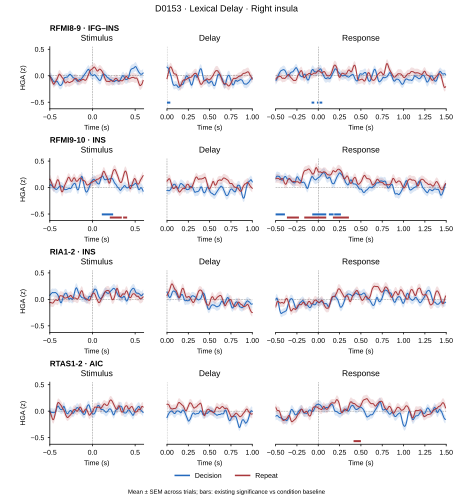

In [3]:
# Compute limits using only displayed samples, across every electrode and condition.
shown = pd.concat([summary.loc[summary.phase.eq(p) & summary.time.between(*w)]
                   for p, w in WINDOWS.items()])
ymin = min(0., float((shown['mean'] - shown['sem']).min()))
ymax = max(0., float((shown['mean'] + shown['sem']).max()))
padding = .10 * (ymax - ymin)
YLIM = (ymin - 3*padding, ymax + padding)
FIGURE_PATHS = []


def draw_figure(channels, filename):
    rows = len(channels)
    fig, axes = plt.subplots(rows, 3, figsize=(16*cm, (2.8 + 3.7*rows)*cm),
                             gridspec_kw={'width_ratios': [1.1, 1., 2.]},
                             sharey=True, squeeze=False)
    fig.subplots_adjust(left=.11, right=.985, top=1-1.65/(2.8+3.7*rows),
                        bottom=1.9/(2.8+3.7*rows), wspace=.20, hspace=.80)
    for row, channel in enumerate(channels):
        for col, (phase, window) in enumerate(WINDOWS.items()):
            ax = axes[row, col]
            for ci, condition in enumerate(CONDITIONS):
                data = traces[channel, condition, phase]
                d = data.loc[data.time.between(*window)]
                ax.plot(d.time, d['mean'], color=COLORS[condition], lw=1)
                ax.fill_between(d.time.to_numpy(), (d['mean']-d['sem']).to_numpy(),
                                (d['mean']+d['sem']).to_numpy(), color=COLORS[condition],
                                alpha=.16, linewidth=0)
                ybar = .10 - .05*ci
                segments = [[(max(a, window[0]), ybar), (min(b, window[1]), ybar)]
                            for a,b in intervals(data.significant, data.time.to_numpy())
                            if a < window[1] and b > window[0]]
                if segments:
                    ax.add_collection(LineCollection(segments, colors=COLORS[condition],
                        linewidths=2, transform=ax.get_xaxis_transform(), clip_on=False))
            ax.axhline(0, color='.55', ls='--', lw=.5, zorder=0)
            ax.axvline(0, color='.55', ls='--', lw=.5, zorder=0)
            ax.set(xlim=window, ylim=YLIM, title=phase, xlabel='Time (s)')
            ax.xaxis.labelpad = 4
            ax.spines[['top','right']].set_visible(False)
            if col == 0:
                ax.set_ylabel('HGA (z)')
                ax.text(0, 1.23, channel.replace('D0153_', '') + '  ·  ' + ROI[channel],
                        transform=ax.transAxes, ha='left', va='bottom', fontsize=8,
                        fontweight='bold')
            else:
                ax.spines['left'].set_visible(False)
                ax.tick_params(axis='y', left=False)
    fig.suptitle('D0153 · Lexical Delay · Right insula', fontsize=9, y=.99)
    handles = [Line2D([0], [0], color=COLORS[c], lw=1.5, label=c) for c in CONDITIONS]
    fig.legend(handles=handles, ncol=2, frameon=False, loc='lower center',
               bbox_to_anchor=(.5, .055 if rows==1 else .025), fontsize=7)
    fig.text(.5, .015 if rows==1 else .006,
             'Mean ± SEM across trials; bars: existing significance vs condition baseline',
             ha='center', va='bottom', fontsize=6)
    fig.savefig(filename, format='svg', facecolor='white')
    plt.close(fig)
    FIGURE_PATHS.append(filename)
    return filename

OVERVIEW = draw_figure(CHANNELS, FIG / 'D0153_LexicalDelay_insula_highgamma_three_phase.svg')
for channel in CHANNELS:
    draw_figure([channel], FIG / f'{channel}_LexicalDelay_highgamma_three_phase.svg')
display(SVG(filename=str(OVERVIEW)))

## 4. Validation and provenance
The notebook checks complete condition/phase/electrode coverage, finite summary values, valid sample counts, and SVG integrity, and verifies upstream file sizes/modification times remained unchanged during visualization. Input hashes and successful upstream job IDs are saved for traceability.

In [4]:
assert len(summary) == len(CHANNELS) * len(CONDITIONS) * len(PHASES) * 320
assert not summary.duplicated(['channel','condition','phase','time']).any()
assert np.isfinite(summary[['mean','sem']].to_numpy()).all()
assert summary.n_valid.between(2, 168).all()
assert set(summary.channel) == set(CHANNELS)
assert set(summary.condition) == set(CONDITIONS)
for path in FIGURE_PATHS:
    tree = ET.parse(path)
    assert tree.getroot().tag.endswith('svg') and path.stat().st_size > 1000
    assert not tree.findall('.//{http://www.w3.org/2000/svg}image'), 'Expected vector-only figures'
for record in pd.read_csv(OUT / 'file_inventory.csv').itertuples():
    st = Path(record.path).stat()
    assert st.st_size == record.bytes and st.st_mtime_ns == record.mtime_ns, record.path
assert digest(ANATOMY) == audit['anatomy_sha256']
validation = dict(subject='D0153', completed_utc=datetime.now(timezone.utc).isoformat(),
                  status='passed', conditions=list(CONDITIONS), displayed_phases=list(WINDOWS),
                  audited_phases=list(PHASES), electrodes=CHANNELS, n_summary_rows=len(summary),
                  trials_per_condition=168, valid_trials_range=[int(summary.n_valid.min()), int(summary.n_valid.max())],
                  statistics='existing baseline tests only; no condition contrast',
                  aggregation='within-electrode trial mean +/- SEM, ddof=1, NaNs omitted samplewise',
                  common_ylim=YLIM, upstream_unchanged=True,
                  upstream_jobs={'clean':58365989,'bipolar':58366351,'highgamma':58368569,
                                 'epoch_validation':58381462,'significance':58381537},
                  upstream_anatomy={'path':str(ANATOMY),'sha256':digest(ANATOMY)},
                  input_hashes=provenance,
                  figures=[dict(path=str(p),sha256=digest(p)) for p in FIGURE_PATHS],
                  audit_limitations=audit['limitation'])
(OUT / 'validation.json').write_text(json.dumps(validation, indent=2))
print('Validated', len(FIGURE_PATHS), 'SVGs; all conditions and insula channels retained.')
print('Output:', FIG)


Validated 5 SVGs; all conditions and insula channels retained.
Output: /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_d0153_highgamma


## 5. D0149 (D149) · Picture Naming · RTAS5–6: audit

The new subject section is independently executable and leaves the D0153 analysis unchanged. User-selected channel: **D0149_RTAS5-6**, right insula (`INS`, `mix=False`) in the task-local aparc2009s table. The bipolar endpoint identities and midpoint coordinates are checked against the signal derivatives. This ROI consensus does not mean both contacts are in insular gray matter: RTAS5 is labeled inferior circular insular sulcus, while midpoint and RTAS6 are white matter.

Completed conditions: **Passive and Repeat**, each for **image, sound, text**. Audit all four phases (including Go); display Stimulus, Delay, Response using the same windows as D0153. This subject has five task recordings; task-local parcellation and 24 effective-significant epoch files are present.

**Passive Response is synthetic:** the preprocessing pipeline places it at GoCue + the subject's median Repeat Go-to-Response latency. Repeat is aligned to actual speech onset. Passive therefore has no vocal-onset response. No events, epochs, or statistical tests are regenerated here.


In [5]:
"""Read-only Picture Naming audit and RTAS5-6 summaries; execute on Slurm."""
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import h5py
import mne
import numpy as np
import pandas as pd

PN_ROOT = Path('/hpc/group/coganlab/nanlinshi/insula-functional')
PN_BIDS = Path('/cwork/ns458/BIDS-1.3_PictureNaming/BIDS')
PN_DERIV = PN_BIDS / 'derivatives'
PN_EPOCH = PN_DERIV / 'epoch(bipolar)/sub-D0149'
PN_OUT = PN_ROOT / 'results/grant_d0149_highgamma'
PN_ANATOMY = PN_DERIV / 'parcellation/sub-D0149/bipolar/sub-D0149_aparc2009s.csv'
PN_CHANNEL = 'D0149_RTAS5-6'
PN_CONDITIONS = ('Passive', 'Repeat')
PN_MODALITIES = ('image', 'sound', 'text')
PN_PHASES = ('Stimulus', 'Delay', 'Go', 'Response')
PN_TEST_WINDOWS = {p: ((-.5, .5) if p == 'Response' else (0., .5)) for p in PN_PHASES}

def pn_digest(path):
    h = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()

def pn_epoch_path(kind, phase, modality, condition):
    task = '' if kind in ('sig', 'effective') else '_task-PictureNaming'
    folder = ('epoch(raw)' if kind == 'raw' else 'epoch(band)(raw)' if kind == 'raw_band'
              else 'epoch(band)(sig)(effective)' if kind == 'effective' else f'epoch(band)({kind})')
    suffix = 'raw' if kind == 'raw' else 'highgamma'
    stem = f'sub-D0149{task}_proc-{phase}_recording-{modality}_desc-{condition}_{suffix}.h5'
    path = PN_EPOCH / folder / stem
    if kind == 'effective' and not path.exists():
        path = path.with_name(stem.replace('sub-D0149_', 'sub-D0149_task-PictureNaming_', 1))
    return path

def pn_stats_path(phase, modality, condition):
    return PN_DERIV / 'statistics/sub-D0149/bipolar' / f'sub-D0149_task-PictureNaming_proc-{phase}_recording-{modality}_desc-{condition}_highgamma.h5'

def pn_intervals(mask, times, sfreq=128):
    changes = np.diff(np.r_[False, np.asarray(mask, bool), False].astype(int))
    return [(float(times[a]), float(times[b-1] + 1/sfreq))
            for a, b in zip(np.flatnonzero(changes == 1), np.flatnonzero(changes == -1))]

def pn_audit():
    PN_OUT.mkdir(parents=True, exist_ok=True)
    inventory, details, summaries, intervals, input_hashes = [], [], [], [], []
    def require(path, stage):
        assert path.is_file() and path.stat().st_size > 0, str(path)
        st = path.stat()
        inventory.append(dict(stage=stage, path=str(path), bytes=st.st_size, mtime_ns=st.st_mtime_ns))
    for stage, base in [('raw', PN_BIDS)] + [(s, PN_DERIV/s) for s in ('clean','delay','bipolar')]:
        folder = base/'sub-D0149/ieeg'
        recordings = sorted(folder.glob('*run-*_ieeg.edf'))
        assert len(recordings) == 5, (stage, len(recordings))
        for edf in recordings:
            require(edf, stage)
            for suffix in ('_ieeg.json', '_events.tsv', '_channels.tsv', '_events.json'):
                path = edf.with_name(edf.name.replace('_ieeg.edf', suffix))
                if not path.exists():
                    matches = list(folder.glob('*' + suffix))
                    assert len(matches) == 1, (stage, suffix, matches)
                    path = matches[0]
                require(path, stage)
        for suffix in ('electrodes.tsv','coordsystem.json'):
            paths = list(folder.glob('*'+suffix))
            assert paths, (stage, suffix)
            for path in paths:
                require(path, stage)
    require(PN_ANATOMY, 'parcellation')
    parc = pd.read_csv(PN_ANATOMY)
    assert parc.name.is_unique
    selected = parc.loc[parc.name.eq(PN_CHANNEL)]
    assert len(selected) == 1 and selected.roi.iloc[0] == 'INS' and not selected.mix.iloc[0]
    assert selected.hemi.iloc[0] == 'R'
    pairs_path = PN_DERIV/'qc/bipolar_pairing/sub-D0149_pairs.tsv'
    for suffix in ('pairs','segments','orphans','skipped'):
        require(pairs_path.with_name(f'sub-D0149_{suffix}.tsv'), 'pairing')
    pairs = pd.read_csv(pairs_path, sep='\t')
    pair = pairs.loc[pairs.bipolar_name.eq(PN_CHANNEL)]
    assert len(pair) == 1 and pair.ch1.iloc[0] == 'RTAS5' and pair.ch2.iloc[0] == 'RTAS6'
    assert selected.contact_1.iloc[0] == 'RTAS5' and selected.contact_2.iloc[0] == 'RTAS6'
    for path in (PN_DERIV/'bipolar/sub-D0149/ieeg').glob('*electrodes.tsv'):
        coords = pd.read_csv(path, sep='\t').set_index('name')
        np.testing.assert_allclose(selected[['x','y','z']].to_numpy(float)[0], coords.loc[PN_CHANNEL,['x','y','z']].to_numpy(float)*1000, atol=1e-6)
    selected.to_csv(PN_OUT/'electrode_anatomy.csv', index=False)
    channels = None
    for modality in PN_MODALITIES:
        for condition in PN_CONDITIONS:
            for phase in ('baseline',) + PN_PHASES:
                for kind in ('raw','power') + (() if phase == 'baseline' else ('raw_band','zscore')):
                    require(pn_epoch_path(kind,phase,modality,condition),kind)
                power = mne.read_epochs(pn_epoch_path('power',phase,modality,condition),preload=True,verbose='error')
                pdata = power.get_data(copy=False)
                assert len(power) > 1 and power.info['sfreq'] == 128
                assert pdata.shape[2] == (64 if phase == 'baseline' else 320) and np.isfinite(pdata).all()
                if channels is None:
                    channels = power.ch_names
                    assert PN_CHANNEL in channels and set(channels).issubset(set(pairs.bipolar_name))
                assert channels == power.ch_names
                if phase == 'baseline':
                    details.append(dict(modality=modality,condition=condition,phase=phase,n_trials=len(power),n_channels=len(channels),n_times=len(power.times)))
                    del pdata,power
                    continue
                path = pn_stats_path(phase,modality,condition)
                require(path,'statistics')
                with h5py.File(path) as f:
                    mask,pvals = f['mask'][:].astype(bool),f['pvals'][:]
                    stat_channels = f['ch_names'].asstr()[:].tolist()
                    sig_channels = f['sig_ch_names'].asstr()[:].tolist()
                zpath = pn_epoch_path('zscore',phase,modality,condition)
                z = mne.read_epochs(zpath,preload=True,verbose='error')
                zdata = z.get_data(copy=False)
                assert channels == stat_channels == z.ch_names
                assert zdata.shape == pdata.shape and np.array_equal(z.events,power.events)
                assert np.array_equal(z.times,power.times) and not np.isinf(zdata).any()
                assert mask.shape == pvals.shape == zdata.shape[1:]
                assert np.isfinite(pvals).all() and ((pvals>=0)&(pvals<=1)).all()
                a,b = z.time_as_index(PN_TEST_WINDOWS[phase])
                window = np.zeros(len(z.times),bool);window[a:b]=True
                expected = np.array(channels)[(mask[:,a:b]&(pvals[:,a:b]<.05)).any(axis=1)].tolist()
                assert expected == sig_channels, (modality,condition,phase,'stored significance mismatch')
                if sig_channels:
                    sigpath = pn_epoch_path('sig',phase,modality,condition)
                    require(sigpath,'sig')
                    sig = mne.read_epochs(sigpath,preload=True,verbose='error')
                    assert sig.ch_names == sig_channels and np.array_equal(z.events,sig.events)
                    np.testing.assert_allclose(sig.get_data(copy=False),z.get_data(picks=sig_channels),equal_nan=True)
                    del sig
                effective_path = pn_epoch_path('effective',phase,modality,condition)
                require(effective_path,'effective')
                effective = mne.read_epochs(effective_path,preload=True,verbose='error')
                assert set(effective.ch_names).issubset(sig_channels)
                np.testing.assert_allclose(effective.get_data(copy=False),z.get_data(picks=effective.ch_names),equal_nan=True)
                del effective
                idx = channels.index(PN_CHANNEL)
                x = zdata[:,idx,:]
                n = np.isfinite(x).sum(axis=0)
                assert (n>=2).all()
                mean,sem = np.nanmean(x,axis=0),np.nanstd(x,axis=0,ddof=1)/np.sqrt(n)
                sig_target = mask[idx]&(pvals[idx]<.05)&window
                assert bool(sig_target.any()) == (PN_CHANNEL in sig_channels)
                summaries.append(pd.DataFrame(dict(subject='D0149',channel=PN_CHANNEL,roi='INS',
                    modality=modality,condition=condition,phase=phase,time=z.times,mean=mean,sem=sem,
                    n_valid=n,n_trials=len(z),cluster_mask=mask[idx],pvalue=pvals[idx],
                    in_analysis_window=window,significant=sig_target)))
                for start,stop in pn_intervals(sig_target,z.times):
                    intervals.append(dict(modality=modality,condition=condition,phase=phase,start_s=start,stop_exclusive_s=stop))
                details.append(dict(modality=modality,condition=condition,phase=phase,n_trials=len(z),
                    n_channels=len(channels),n_times=len(z.times),n_nan_all_channels=int(np.isnan(zdata).sum()),
                    min_valid_target=int(n.min()),max_valid_target=int(n.max()),n_significant=len(sig_channels),
                    target_significant=bool(sig_target.any())))
                input_hashes.extend(dict(path=str(p),sha256=pn_digest(p)) for p in (path,zpath))
                print(modality,condition,phase,'OK; RTAS5-6 significant:',bool(sig_target.any()),flush=True)
                del pdata,power,zdata,z,x
    frame = pd.concat(summaries,ignore_index=True)
    assert len(frame) == 3*2*4*320 and np.isfinite(frame[['mean','sem']]).all().all()
    frame.to_csv(PN_OUT/'timecourse_mean_sem.csv',index=False)
    pd.DataFrame(details).to_csv(PN_OUT/'epoch_audit.csv',index=False)
    pd.DataFrame(intervals,columns=['modality','condition','phase','start_s','stop_exclusive_s']).to_csv(PN_OUT/'significant_intervals.csv',index=False)
    pd.DataFrame(inventory).drop_duplicates('path').to_csv(PN_OUT/'file_inventory.csv',index=False)
    report = dict(subject='D0149',display_subject='D149',task='PictureNaming',channel=PN_CHANNEL,
        status='passed',completed_utc=datetime.now(timezone.utc).isoformat(),n_recordings=5,
        n_bipolar_channels=len(channels),conditions=PN_CONDITIONS,modalities=PN_MODALITIES,
        phases=PN_PHASES,statistics_count=24,effective_epoch_count=24,anatomy_source=str(PN_ANATOMY),
        anatomy_sha256=pn_digest(PN_ANATOMY),input_hashes=input_hashes,
        passive_response='Synthetic alignment at GoCue plus subject median Repeat reaction time; not a vocal onset.',
        note='All requested channel trials retained regardless of significance. Raw EDF data are inventoried, not reprocessed. TFR/decoding are outside this temporal HGA audit.')
    (PN_OUT/'audit.json').write_text(json.dumps(report,indent=2))
    print('AUDIT PASSED:',PN_CHANNEL,flush=True)
    return report,frame,pd.DataFrame(details)


from IPython.display import display, SVG
pn_report, pn_summary, pn_details = pn_audit()
display(pd.read_csv(PN_OUT/'electrode_anatomy.csv'))
display(pn_details)


image Passive Stimulus OK; RTAS5-6 significant: False
image Passive Delay OK; RTAS5-6 significant: False
image Passive Go OK; RTAS5-6 significant: False
image Passive Response OK; RTAS5-6 significant: False
image Repeat Stimulus OK; RTAS5-6 significant: False
image Repeat Delay OK; RTAS5-6 significant: False
image Repeat Go OK; RTAS5-6 significant: False
image Repeat Response OK; RTAS5-6 significant: True
sound Passive Stimulus OK; RTAS5-6 significant: True
sound Passive Delay OK; RTAS5-6 significant: True
sound Passive Go OK; RTAS5-6 significant: False
sound Passive Response OK; RTAS5-6 significant: False
sound Repeat Stimulus OK; RTAS5-6 significant: True
sound Repeat Delay OK; RTAS5-6 significant: True
sound Repeat Go OK; RTAS5-6 significant: False
sound Repeat Response OK; RTAS5-6 significant: True
text Passive Stimulus OK; RTAS5-6 significant: False
text Passive Delay OK; RTAS5-6 significant: False
text Passive Go OK; RTAS5-6 significant: False
text Passive Response OK; RTAS5-6 si

,subject,name,x,y,z,x1,y1,z1,x2,y2,...,z2_mni,x_t,y_t,z_t,x1_t,y1_t,z1_t,x2_t,y2_t,z2_t
0,D0149,D0149_RTAS5-6,47.16665,-1.14285,-2.78565,45.4,-1.2,-2.6,48.9333,-1.0857,...,-1.70442,53.8549,9.93795,-20.60912,51.5172,9.58257,-20.57013,56.3349,10.21428,-20.70442


,modality,condition,phase,n_trials,n_channels,n_times,n_nan_all_channels,min_valid_target,max_valid_target,n_significant,target_significant
0,image,Passive,baseline,120,148,64,NaN,NaN,NaN,NaN,NaN
1,image,Passive,Stimulus,40,148,320,13440.0,40.0,40.0,19.0,False
2,image,Passive,Delay,40,148,320,8640.0,40.0,40.0,9.0,False
3,image,Passive,Go,40,148,320,13760.0,40.0,40.0,4.0,False
4,image,Passive,Response,40,148,320,12480.0,40.0,40.0,19.0,False
5,image,Repeat,baseline,240,148,64,NaN,NaN,NaN,NaN,NaN
6,image,Repeat,Stimulus,80,148,320,15680.0,80.0,80.0,29.0,False
7,image,Repeat,Delay,80,148,320,17280.0,80.0,80.0,11.0,False
8,image,Repeat,Go,80,148,320,14080.0,80.0,80.0,26.0,False
9,image,Repeat,Response,78,148,320,24960.0,78.0,78.0,57.0,True


## 6. D0149: three-phase waveforms

Use saved 70–200 Hz high-gamma z-score epochs, sampled at 128 Hz. Each condition uses its own StartCue baseline (−0.5 to 0 s), shared across modalities in the upstream extraction. Plot all valid trials in the requested channel, without significance-based selection, extra smoothing, or re-normalization. Ribbons are ±SEM across trials (`ddof=1`, omitting upstream outlier NaNs samplewise).

Blue = Passive; red = Repeat. Colored bars indicate saved cluster mask AND saved p-value < .05, restricted to the upstream decision window: [0, .5) s for Stimulus/Delay/Go, [−.5, .5) s for Response. These are existing condition-vs-baseline tests, **not a Passive–Repeat comparison**. Outside the decision window, no significance bar is displayed. Exported counts show valid trials per time sample.

Use one common y scale across all three modalities and their separate exports. D0149 and D0153 each have their own y scale. The three phases are independently event-aligned, not a continuous trial timeline.

For the selected grant display, retain **sound only**. Image and text are still audited and archived as separate exports.


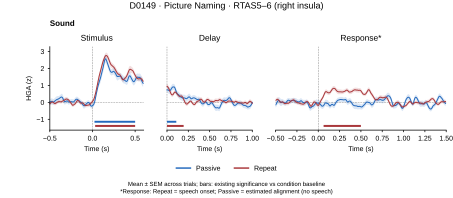

In [6]:
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
import xml.etree.ElementTree as ET

PN_FIG = PN_ROOT/'img/grant_d0149_highgamma'
PN_FIG.mkdir(parents=True, exist_ok=True)
PN_WINDOWS = {'Stimulus':(-.5,.6), 'Delay':(0.,1.), 'Response':(-.5,1.5)}
PN_COLORS = {'Passive':'#2369BD', 'Repeat':'#A9373B'}
PN_CM = 1/2.54
for pn_font in (Path(sys.prefix)/'fonts').glob('arial*.ttf'):
    font_manager.fontManager.addfont(str(pn_font))
font_manager.findfont('Arial', fallback_to_default=False)
plt.rcParams.update({'svg.fonttype':'none','font.family':'sans-serif',
    'font.sans-serif':['Arial'],'font.size':7,'axes.linewidth':.75,
    'xtick.major.width':.75,'ytick.major.width':.75,'xtick.major.size':2,'ytick.major.size':2})
pn_shown = pd.concat([pn_summary.loc[pn_summary.phase.eq(p)&pn_summary.time.between(*w)]
                      for p,w in PN_WINDOWS.items()])
pn_ymin = min(0.,float((pn_shown['mean']-pn_shown['sem']).min()))
pn_ymax = max(0.,float((pn_shown['mean']+pn_shown['sem']).max()))
pn_pad = .1*(pn_ymax-pn_ymin)
assert pn_pad > 0
PN_YLIM = (pn_ymin-3*pn_pad,pn_ymax+pn_pad)
PN_FIGURES = []

def pn_draw(modalities, filename):
    rows = len(modalities)
    height_cm = 3.3+3.7*rows
    fig,axes = plt.subplots(rows,3,figsize=(16*PN_CM,height_cm*PN_CM),
        gridspec_kw={'width_ratios':[1.1,1.,2.]},sharey=True,squeeze=False)
    fig.subplots_adjust(left=.11,right=.985,top=1-1.65/height_cm,
        bottom=2.4/height_cm,wspace=.20,hspace=.80)
    for row,modality in enumerate(modalities):
        for col,(phase,window) in enumerate(PN_WINDOWS.items()):
            ax=axes[row,col]
            for ci,condition in enumerate(PN_CONDITIONS):
                data=pn_summary.loc[pn_summary.modality.eq(modality)&pn_summary.condition.eq(condition)&pn_summary.phase.eq(phase)]
                d=data.loc[data.time.between(*window)]
                ax.plot(d.time,d['mean'],color=PN_COLORS[condition],lw=1)
                ax.fill_between(d.time.to_numpy(),(d['mean']-d['sem']).to_numpy(),
                    (d['mean']+d['sem']).to_numpy(),color=PN_COLORS[condition],alpha=.16,linewidth=0)
                ybar=.10-.05*ci
                segments=[[(max(a,window[0]),ybar),(min(b,window[1]),ybar)]
                    for a,b in pn_intervals(data.significant,data.time.to_numpy())
                    if a<window[1] and b>window[0]]
                if segments:
                    ax.add_collection(LineCollection(segments,colors=PN_COLORS[condition],
                        linewidths=2,transform=ax.get_xaxis_transform(),clip_on=False))
            ax.axhline(0,color='.55',ls='--',lw=.5,zorder=0)
            ax.axvline(0,color='.55',ls='--',lw=.5,zorder=0)
            ax.set(xlim=window,ylim=PN_YLIM,title=phase+('*' if phase=='Response' else ''),xlabel='Time (s)')
            ax.xaxis.labelpad=4
            ax.spines[['top','right']].set_visible(False)
            if col==0:
                ax.set_ylabel('HGA (z)')
                ax.text(0,1.23,modality.capitalize(),transform=ax.transAxes,
                    ha='left',va='bottom',fontsize=8,fontweight='bold')
            else:
                ax.spines['left'].set_visible(False)
                ax.tick_params(axis='y',left=False)
    fig.suptitle('D0149 · Picture Naming · RTAS5–6 (right insula)',fontsize=9,y=.99)
    handles=[Line2D([0],[0],color=PN_COLORS[c],lw=1.5,label=c) for c in PN_CONDITIONS]
    fig.legend(handles=handles,ncol=2,frameon=False,loc='lower center',
        bbox_to_anchor=(.5,.70/height_cm),fontsize=7)
    fig.text(.5,.12/height_cm,
        'Mean ± SEM across trials; bars: existing significance vs condition baseline\n'
        '*Response: Repeat = speech onset; Passive = estimated alignment (no speech)',
        ha='center',va='bottom',fontsize=6,linespacing=1.4)
    fig.savefig(filename,format='svg',facecolor='white')
    plt.close(fig)
    PN_FIGURES.append(filename)
    return filename

PN_OVERVIEW=pn_draw(PN_MODALITIES,PN_FIG/'D0149_RTAS5-6_PictureNaming_highgamma_three_phase.svg')
for pn_modality in PN_MODALITIES:
    pn_draw([pn_modality],PN_FIG/f'D0149_RTAS5-6_PictureNaming_{pn_modality}_highgamma_three_phase.svg')
display(SVG(filename=str(PN_FIG/'D0149_RTAS5-6_PictureNaming_sound_highgamma_three_phase.svg')))


## 7. D0149: trial counts and existing significance
All requested modalities and conditions are retained, including non-significant curves. Go is included in this audit table but not in the three-phase figure. No between-condition inference is made.

In [7]:
pn_stats=pn_details.loc[pn_details.phase.ne('baseline'),[
    'modality','condition','phase','n_trials','min_valid_target','max_valid_target','target_significant']].copy()
pn_stats.to_csv(PN_OUT/'RTAS5-6_significance_summary.csv',index=False)
display(pn_stats)
display(pd.read_csv(PN_OUT/'significant_intervals.csv'))


,modality,condition,phase,n_trials,min_valid_target,max_valid_target,target_significant
1,image,Passive,Stimulus,40,40.0,40.0,False
2,image,Passive,Delay,40,40.0,40.0,False
3,image,Passive,Go,40,40.0,40.0,False
4,image,Passive,Response,40,40.0,40.0,False
6,image,Repeat,Stimulus,80,80.0,80.0,False
7,image,Repeat,Delay,80,80.0,80.0,False
8,image,Repeat,Go,80,80.0,80.0,False
9,image,Repeat,Response,78,78.0,78.0,True
11,sound,Passive,Stimulus,40,40.0,40.0,True
12,sound,Passive,Delay,40,40.0,40.0,True


,modality,condition,phase,start_s,stop_exclusive_s
0,image,Repeat,Response,0.007812,0.125000
1,image,Repeat,Response,0.148438,0.500000
2,sound,Passive,Stimulus,0.023438,0.500000
3,sound,Passive,Delay,0.000000,0.109375
4,sound,Repeat,Stimulus,0.031250,0.500000
5,sound,Repeat,Delay,0.000000,0.195312
6,sound,Repeat,Response,0.062500,0.500000
7,text,Repeat,Response,0.015625,0.500000


## 8. D0149: output validation and provenance
Verify complete coverage, finite summaries, vector-only SVG exports, unchanged upstream input metadata, and unchanged anatomy hash. These checks reuse existing statistics; no preprocessing outputs are modified.

In [8]:
assert len(pn_summary)==3*2*4*320
assert not pn_summary.duplicated(['modality','condition','phase','time']).any()
assert np.isfinite(pn_summary[['mean','sem']].to_numpy()).all()
assert ((pn_summary.n_valid>=2)&(pn_summary.n_valid<=pn_summary.n_trials)).all()
assert set(pn_summary.modality)==set(PN_MODALITIES)
assert set(pn_summary.condition)==set(PN_CONDITIONS)
assert len(PN_FIGURES)==4
for pn_path in PN_FIGURES:
    pn_tree=ET.parse(pn_path)
    assert pn_tree.getroot().tag.endswith('svg') and pn_path.stat().st_size>1000
    assert not pn_tree.findall('.//{http://www.w3.org/2000/svg}image')
for pn_record in pd.read_csv(PN_OUT/'file_inventory.csv').itertuples():
    pn_stat=Path(pn_record.path).stat()
    assert pn_stat.st_size==pn_record.bytes and pn_stat.st_mtime_ns==pn_record.mtime_ns,pn_record.path
assert pn_digest(PN_ANATOMY)==pn_report['anatomy_sha256']
pn_validation=dict(subject='D0149',channel=PN_CHANNEL,task='PictureNaming',status='passed',
    completed_utc=datetime.now(timezone.utc).isoformat(),modalities=list(PN_MODALITIES),
    conditions=list(PN_CONDITIONS),displayed_phases=list(PN_WINDOWS),audited_phases=list(PN_PHASES),
    n_summary_rows=len(pn_summary),common_ylim=PN_YLIM,upstream_unchanged=True,
    aggregation='Within-channel trial mean +/- SEM, ddof=1, omitting NaNs samplewise',
    significance='Existing condition-vs-baseline tests only; no Passive-Repeat comparison',
    passive_response=pn_report['passive_response'],
    trial_counts=pn_stats.to_dict('records'),input_hashes=pn_report['input_hashes'],
    anatomy_sha256=pn_report['anatomy_sha256'],
    figures=[dict(path=str(f),sha256=pn_digest(f)) for f in PN_FIGURES])
(PN_OUT/'validation.json').write_text(json.dumps(pn_validation,indent=2))
print('Validated D0149 RTAS5-6: 3 modalities × 2 conditions; 4 SVGs.')
print('Figures:',PN_FIG)


Validated D0149 RTAS5-6: 3 modalities × 2 conditions; 4 SVGs.
Figures: /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_d0149_highgamma


## 9. Selected grant panels: spatial localization + temporal responses

This is the revised display: **D0149 Picture Naming sound only**, and **D0153 including RFMI8–9** explicitly labeled IFG–INS boundary. Earlier per-modality exports remain available for auditing.

**Why RFMI8–9 was initially excluded:** the initial figure used nonmixed INS/AIC/PIC channels. The existing table labels RFMI8 and its midpoint as IFG opercular, RFMI9 as superior circular insular sulcus; their consensus is IFG–INS, `mix=True`. The user requested its inclusion as a boundary channel. RFMI9–10 is INS under the pipeline's different case: its midpoint and RFMI10 are white matter, which is ignored in the consensus. Neither designation proves that both endpoints are in insular gray matter.

**Previous spatial methods reused:** `notebooks/shi100_insula_contacts.ipynb` supplies the native pial insula geometry, Hammers surface display, orthographic camera and fixed 86 mm field. `scripts/qc_ccep_insula_locations.py` supplies the midpoint MRI slice convention for D149 RTAS5–6 and D153 RFMI8–9 / RFMI9–10. The new panels preserve actual tkRAS points without snapping. The surface map is for orientation; the additional MRI figure shows Destrieux insula and IFG boundaries to inspect tissue assignment. The midpoint slice coordinate is shown; endpoint offsets remain in the audit CSV.

Surface coloring follows the existing AIC/PIC display: pale gold = AIC, blue-gray = PIC, pale gray = unresolved. Nearest-GM filling (up to 8 mm) is only for the surface rendering and never changes electrode labels. Only virtual bipolar midpoint crosses are displayed; endpoint coordinates remain in the audit table.

All waveforms use the audited trial means and existing statistical masks from preceding sections. No new test, anatomical relabeling, or manual response coding is performed.


**Compact revision:** all figures are at most 18 cm wide. RFMI9–10 has its own figure. Y limits follow the displayed mean ± SEM envelope with 5% lower and 7% upper margins; significance bars occupy a separate strip, so they do not force the y axis downward. The four-channel D0153 overview retains a shared scale. Exported text bounds, text overlaps, and physical SVG dimensions are checked.

**Repeat-only grant set:** three matching 18 × 6 cm figures: D0153 RFMI9–10, D0149 RTAS5–6 (Picture Naming sound), and D0153 RFMI8–9 (IFG–INS boundary). Only Repeat is shown, in red, with mean ± SEM and existing baseline-significance bars. Repeat Response uses speech-onset alignment. Bottom legends and footnotes are removed; condition and boundary status remain in the titles. Brain anatomy, boundaries, midpoint, and scale bar are enlarged together by 30% within the unchanged panel; canvas size and all time-panel positions remain unchanged. Earlier comparison figures remain exported but are not displayed in this final set.

**D0153 shared display range:** the Repeat-only RFMI8–9 and RFMI9–10 figures both use `ylim=(-0.2, 0.45)` for all three phases, as requested. Values outside this display range are clipped at the axes; source means, SEM, and significance masks are unchanged. D0149 retains its previous range.


2026-10-12 14:21:10 - INFO - Loaded native atlas /cwork/ns458/ECoG_Recon/D153/mri/aparc.a2009s+aseg.mgz


pixdim[0] (qfac) should be 1 (default) or -1; setting qfac to 1


2026-10-12 14:21:10 - INFO - pixdim[0] (qfac) should be 1 (default) or -1; setting qfac to 1


2026-10-12 14:21:11 - INFO - Loaded MAPER seg95 /cwork/ns458/maper_run/D0153/output/f30-seg95-D0153.nii.gz GM-gated by /cwork/ns458/maper_run/D0153/output/f30-seg95-D0153-tc3crisp.nii.gz (693832 GM-labeled voxels; geometry from /cwork/ns458/ECoG_Recon/D153/mri/orig.mgz)


2026-10-12 14:21:16 - INFO - Loaded native atlas /cwork/ns458/ECoG_Recon/D149/mri/aparc.a2009s+aseg.mgz


pixdim[0] (qfac) should be 1 (default) or -1; setting qfac to 1


2026-10-12 14:21:16 - INFO - pixdim[0] (qfac) should be 1 (default) or -1; setting qfac to 1


2026-10-12 14:21:16 - INFO - Loaded MAPER seg95 /cwork/ns458/maper_run/D0149/output/f30-seg95-D0149.nii.gz GM-gated by /cwork/ns458/maper_run/D0149/output/f30-seg95-D0149-tc3crisp.nii.gz (472970 GM-labeled voxels; geometry from /cwork/ns458/ECoG_Recon/D149/mri/orig.mgz)


Validated spatial/temporal panels:
/hpc/group/coganlab/nanlinshi/insula-functional/img/grant_subject_spatiotemporal/D0153_RFMI9-10_LexicalDelay_spatiotemporal.svg
/hpc/group/coganlab/nanlinshi/insula-functional/img/grant_subject_spatiotemporal/D0149_PictureNaming_sound_RTAS5-6_spatiotemporal.svg
/hpc/group/coganlab/nanlinshi/insula-functional/img/grant_subject_spatiotemporal/D0153_LexicalDelay_spatiotemporal.svg
/hpc/group/coganlab/nanlinshi/insula-functional/img/grant_subject_spatiotemporal/D0149_D0153_native_MRI_pair_QC.svg
/hpc/group/coganlab/nanlinshi/insula-functional/img/grant_subject_spatiotemporal/D0153_RFMI9-10_LexicalDelay_Repeat_spatiotemporal.svg
/hpc/group/coganlab/nanlinshi/insula-functional/img/grant_subject_spatiotemporal/D0149_PictureNaming_sound_RTAS5-6_Repeat_spatiotemporal.svg
/hpc/group/coganlab/nanlinshi/insula-functional/img/grant_subject_spatiotemporal/D0153_RFMI8-9_LexicalDelay_Repeat_spatiotemporal.svg


,subject,channel,role,contact,aparc_label,hammers_gm_label,channel_roi,mixed
0,D0153,D0153_RFMI8-9,contact_1,RFMI8,ctx_rh_G_front_inf-Opercular,FL precentral gyrus R,IFG–INS,True
1,D0153,D0153_RFMI8-9,midpoint,BP center,ctx_rh_G_front_inf-Opercular,FL precentral gyrus R,IFG–INS,True
2,D0153,D0153_RFMI8-9,contact_2,RFMI9,ctx_rh_S_circular_insula_sup,FL precentral gyrus R,IFG–INS,True
3,D0153,D0153_RFMI9-10,contact_1,RFMI9,ctx_rh_S_circular_insula_sup,FL precentral gyrus R,INS,False
4,D0153,D0153_RFMI9-10,midpoint,BP center,Right-Cerebral-White-Matter,0,INS,False
5,D0153,D0153_RFMI9-10,contact_2,RFMI10,Right-Cerebral-White-Matter,0,INS,False
6,D0153,D0153_RIA1-2,contact_1,RIA1,ctx_rh_S_circular_insula_sup,FL inferior frontal gyrus R,INS,False
7,D0153,D0153_RIA1-2,midpoint,BP center,Right-Cerebral-White-Matter,FL inferior frontal gyrus R,INS,False
8,D0153,D0153_RIA1-2,contact_2,RIA2,Right-Cerebral-White-Matter,0,INS,False
9,D0153,D0153_RTAS1-2,contact_1,RTAS1,ctx_rh_G_Ins_lg_and_S_cent_ins,insula anterior pole R,AIC,False


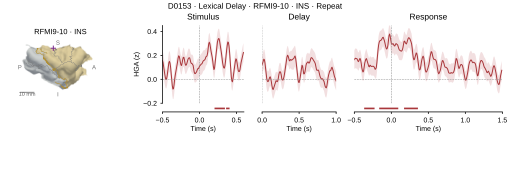

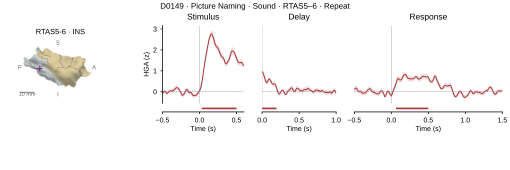

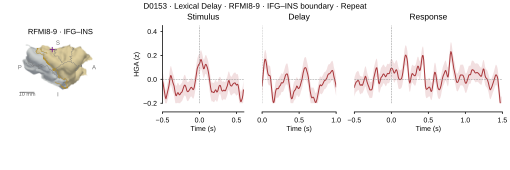

In [1]:
import sys
import importlib
from pathlib import Path
from IPython.display import SVG, display
SPATIAL_ROOT = Path('/hpc/group/coganlab/nanlinshi/insula-functional')
if str(SPATIAL_ROOT/'scripts') not in sys.path:
    sys.path.insert(0, str(SPATIAL_ROOT/'scripts'))
import plot_grant_subject_spatiotemporal as grant_spatial
importlib.reload(grant_spatial)
spatial_paths, spatial_labels = grant_spatial.main()
display(spatial_labels[['subject','channel','role','contact','aparc_label','hammers_gm_label','channel_roi','mixed']])
for spatial_path in spatial_paths:
    if "_Repeat_" not in spatial_path.name:
        continue
    display(SVG(filename=str(spatial_path)))


## CCEP receiving contacts and latency — revised anatomical display

Latencies are user-provided, with unknown onset/peak definition, and are labeled **CCEP latency (ms)**. The three stimulation pairs and all 8 receiving entries are unchanged. Names preserve input polarity/order for geometry lookup.

Electrode names and latency labels are placed beside markers, without leader lines. The D0149 RTMS detail uses native coronal MRI at y = −12 mm to show the mediolateral shaft and gray/white-matter context. Native bipolar midpoints are projected in x/z; all lie less than 1 mm from this slice. Pure lateral projection collapses their depth. All views share the linear 0–150 ms viridis scale.

For pairs originally labeled WM, the displayed ROI is the label of the nearest right-hemisphere gray-matter voxel center in native aparc2009s+aseg (cortical or subcortical). A dagger identifies this naming convention; physical coordinates are unchanged. The original tissue label, nearest full gray-matter label, native coordinates and distance in mm are retained in `electrode_anatomy.csv`.

**Stimulation markers are removed from intact cortical views.** Each figure includes an exposed-insula inset and a native coronal MRI slice through the nearest voxel plane to the stimulation midpoint. The MRI white-matter boundary and actual midpoint tissue label distinguish gray matter from white matter. Insets show virtual bipolar midpoints only; cortical projections alone do not establish tissue membership.

Independent SVGs are 18 × 10 cm. The optional vertical overview is 18 × 30 cm; individual figures are intended for separate placement in the grant.


In [1]:
from pathlib import Path
import sys, importlib
ROOT=Path('/hpc/group/coganlab/nanlinshi/insula-functional')
for folder in [ROOT, ROOT/'scripts']:
    if str(folder) not in sys.path: sys.path.insert(0,str(folder))
import plot_grant_ccep_receivers as ccep
importlib.reload(ccep)
from IPython.display import SVG, display
CCEP_RECORDS = [
 dict(subject='D0149', stimulus='RTAS5–RTAS6', receivers=[
     dict(pair='RTMS4–RTMS3', latency_ms=57.13),
     dict(pair='RTMS6–RTMS5', latency_ms=8.30),
     dict(pair='RTMS7–RTMS6', latency_ms=62.99),
     dict(pair='RTMS8–RTMS7', latency_ms=125.98),
     dict(pair='RTAM9–RTAM8', latency_ms=138.18)]),
 dict(subject='D0153', stimulus='RFMI8–RFMI9', receivers=[
     dict(pair='RFPM2–RFPM1', latency_ms=70.31),
     dict(pair='RIA6–RIA5', latency_ms=66.41)]),
 dict(subject='D0153', stimulus='RFMI9–RFMI10', receivers=[
     dict(pair='RIA6–RIA5', latency_ms=62.50)])
]


In [2]:
ccep_validation=ccep.main(CCEP_RECORDS)
display(ccep.pd.read_csv(ccep.OUT/'electrode_anatomy.csv')[
    ['subject','pair','roi','display_roi','nearest_gm_label','nearest_gm_distance_mm','midpoint_label','x','y','z']])


2026-10-12 16:57:54 - INFO - Loaded native atlas /cwork/ns458/ECoG_Recon/D149/mri/aparc.a2009s+aseg.mgz


2026-10-12 16:58:02 - INFO - Loaded native atlas /cwork/ns458/ECoG_Recon/D153/mri/aparc.a2009s+aseg.mgz


subject         pair     roi display_roi              nearest_gm_label  nearest_gm_distance_mm                midpoint_label
  D0149  RTAS5–RTAS6     INS         INS  ctx_rh_S_circular_insula_inf                1.413762   Right-Cerebral-White-Matter
  D0149  RTMS4–RTMS3      WM          HG  ctx_rh_S_temporal_transverse                1.111810   Right-Cerebral-White-Matter
  D0149  RTMS6–RTMS5     STG         STG     ctx_rh_G_temp_sup-Lateral                0.686911   Right-Cerebral-White-Matter
  D0149  RTMS7–RTMS6     STG         STG     ctx_rh_G_temp_sup-Lateral                0.535640     ctx_rh_G_temp_sup-Lateral
  D0149  RTMS8–RTMS7     STG         STG     ctx_rh_G_temp_sup-Lateral                0.268929     ctx_rh_G_temp_sup-Lateral
  D0149  RTAM9–RTAM8      WM          TP          ctx_rh_Pole_temporal                2.681090   Right-Cerebral-White-Matter
  D0153  RFMI8–RFMI9 IFG–INS     IFG–INS  ctx_rh_G_front_inf-Opercular                0.612372  ctx_rh_G_front_inf-Opercular


Validated 5 / 2 / 1 receiver entries and four SVGs.


,subject,pair,roi,display_roi,nearest_gm_label,nearest_gm_distance_mm,midpoint_label,x,y,z
0,D0149,RTAS5–RTAS6,INS,INS,ctx_rh_S_circular_insula_inf,1.413762,Right-Cerebral-White-Matter,47.16665,-1.14285,-2.78565
1,D0149,RTMS4–RTMS3,WM,HG,ctx_rh_S_temporal_transverse,1.111810,Right-Cerebral-White-Matter,47.75000,-12.75000,5.33335
2,D0149,RTMS6–RTMS5,STG,STG,ctx_rh_G_temp_sup-Lateral,0.686911,Right-Cerebral-White-Matter,54.46430,-11.96450,4.57150
3,D0149,RTMS7–RTMS6,STG,STG,ctx_rh_G_temp_sup-Lateral,0.535640,ctx_rh_G_temp_sup-Lateral,57.77385,-11.60750,4.28585
4,D0149,RTMS8–RTMS7,STG,STG,ctx_rh_G_temp_sup-Lateral,0.268929,ctx_rh_G_temp_sup-Lateral,61.13100,-11.21475,3.90490
5,D0149,RTAM9–RTAM8,WM,TP,ctx_rh_Pole_temporal,2.681090,Right-Cerebral-White-Matter,39.98125,9.16875,-19.24375
6,D0153,RFMI8–RFMI9,IFG–INS,IFG–INS,ctx_rh_G_front_inf-Opercular,0.612372,ctx_rh_G_front_inf-Opercular,42.25000,13.75000,8.50000
7,D0153,RFPM2–RFPM1,CG,CG,ctx_rh_G_and_S_cingul-Mid-Ant,0.707107,ctx_rh_G_and_S_cingul-Mid-Ant,6.50000,27.00000,26.50000
8,D0153,RIA6–RIA5,WM,MFGs,ctx_rh_S_front_middle,2.536013,Right-Cerebral-White-Matter,28.55000,35.64585,27.89165
9,D0153,RFMI9–RFMI10,INS,INS,ctx_rh_S_circular_insula_sup,0.733693,Right-Cerebral-White-Matter,47.03575,14.53575,9.50000


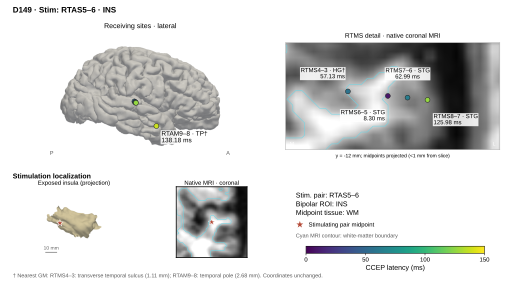

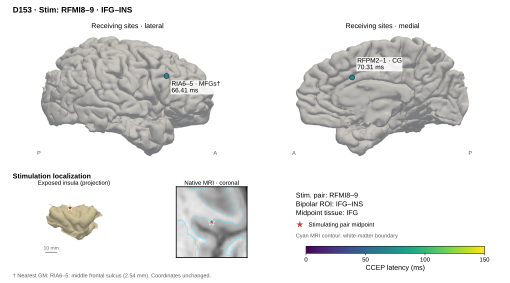

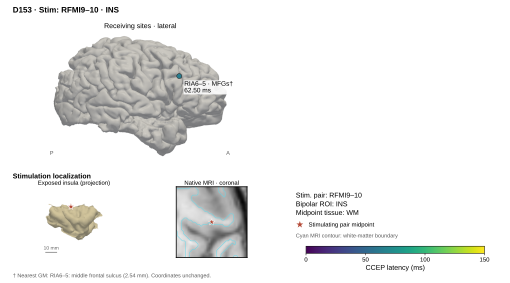

Combined SVG: /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_ccep_receivers/CCEP_receivers_three_panels.svg


In [3]:
for panel in ccep_validation['figures'][:3]:
    display(SVG(filename=panel['path']))
print('Combined SVG:', ccep_validation['figures'][-1]['path'])


## D0153 RIA5–6 · task HGA at the CCEP receiving pair

Same contact pair as the CCEP entry RIA6–RIA5. This section shows **Lexical Delay, Repeat task HGA**, not stimulation-locked CCEP voltage. First verify all required epoch/statistics files and target-channel significance, then render from the audited summaries.

Use saved 70–200 Hz HGA z-score epochs at 128 Hz, condition-specific cue baseline −0.5–0 s. Red line: trial mean; ribbon: ±SEM (samplewise valid counts, ddof=1). Bars: saved cluster mask AND p < .05 in the original decision windows. No new tests, smoothing, or significance-based trial selection. Display Stimulus −0.5–0.6 s, Delay 0–1 s, Response −0.5–1.5 s. Shared y limits adapt to this electrode's full displayed mean ±SEM range; the old RFMI-specific limits do not apply.

The native bipolar midpoint is **white matter, nearest gray-matter label MFGs (middle frontal sulcus)**. The lateral brain inset shows its projection with unchanged native coordinates. Export: 18 × 6 cm SVG, no bottom legend. Existing figures and analyses are retained.


In [1]:
from pathlib import Path
import sys, importlib
from IPython.display import SVG, display
RIA_ROOT=Path('/hpc/group/coganlab/nanlinshi/insula-functional')
if str(RIA_ROOT/'scripts') not in sys.path: sys.path.insert(0,str(RIA_ROOT/'scripts'))
import plot_grant_d0153_ria56 as ria56
importlib.reload(ria56)
ria_report=ria56.audit_and_summarize()
display(ria56.pd.read_csv(ria56.OUT/'significance_summary.csv'))
display(ria56.pd.read_csv(ria56.OUT/'electrode_anatomy.csv')[['canonical_channel','roi','display_roi','nearest_gm_label','nearest_gm_distance_mm']])


2026-10-13 13:37:54 - INFO - Loaded native atlas /cwork/ns458/ECoG_Recon/D153/mri/aparc.a2009s+aseg.mgz


Stimulus {'phase': 'Stimulus', 'condition': 'Repeat', 'n_trials': 168, 'min_valid_trials': 168, 'max_valid_trials': 168, 'significant': False}


Delay {'phase': 'Delay', 'condition': 'Repeat', 'n_trials': 168, 'min_valid_trials': 168, 'max_valid_trials': 168, 'significant': False}


Go {'phase': 'Go', 'condition': 'Repeat', 'n_trials': 168, 'min_valid_trials': 168, 'max_valid_trials': 168, 'significant': True}


Response {'phase': 'Response', 'condition': 'Repeat', 'n_trials': 168, 'min_valid_trials': 168, 'max_valid_trials': 168, 'significant': True}


,phase,condition,n_trials,min_valid_trials,max_valid_trials,significant
0,Stimulus,Repeat,168,168,168,False
1,Delay,Repeat,168,168,168,False
2,Go,Repeat,168,168,168,True
3,Response,Repeat,168,168,168,True


,canonical_channel,roi,display_roi,nearest_gm_label,nearest_gm_distance_mm
0,D0153_RIA5-6,WM,MFGs,ctx_rh_S_front_middle,2.536013


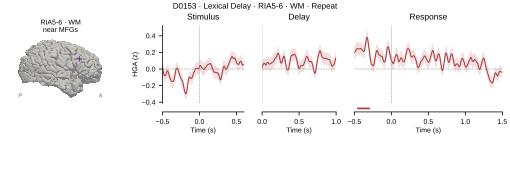

Figure: /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_d0153_ria56/D0153_RIA5-6_LexicalDelay_Repeat_spatiotemporal.svg
Validation: {'channels': ['D0153_RIA5-6'], 'conditions': ['Repeat'], 'ylim': [-0.4126701135652257, 0.5240954791149303], 'brain_display_zoom': 1.0, 'bottom_legend': False, 'envelope_min': -0.3708502210348616, 'envelope_max': 0.4655476295724205, 'significance_location': 'separate strip below waveform; no extra y-range', 'path': '/hpc/group/coganlab/nanlinshi/insula-functional/img/grant_d0153_ria56/D0153_RIA5-6_LexicalDelay_Repeat_spatiotemporal.svg', 'width_cm': 17.999999983333332, 'height_cm': 5.999999994444445, 'text_overlap_check': 'passed', 'text_clipping_check': 'passed', 'figure_sha256': '6452a075a2d27822691559779a8bcbcc35bb89be9aa6b0d844b5552336b880e0', 'localization': 'Native virtual bipolar midpoint; WM, nearest gray matter MFGs; coordinates not snapped', 'windows': {'Stimulus': (-0.5, 0.6), 'Delay': (0, 1), 'Response': (-0.5, 1.5)}, 'embedded_brain_p

In [2]:
ria_path,ria_validation=ria56.render()
display(SVG(filename=str(ria_path)))
print('Figure:',ria_path)
print('Validation:',ria_validation)


## D0153 RIA5–6 · Decision HGA (separate export)

Additional **Lexical Delay · Decision** version. The existing Repeat cells, summaries, and SVG are preserved. Use the same upstream audit, native midpoint localization, 1200 × 800 brain image, three display windows, and 18 × 6 cm layout. Blue = Decision (the original project condition color); ribbon = ±SEM, bars = existing significance. The y range is based on the displayed Decision mean ±SEM. No bottom legend. Decision data and exports are isolated in directories ending `_decision`.


In [1]:
from pathlib import Path
import sys, importlib
from IPython.display import SVG, display
RIA_DEC_ROOT=Path('/hpc/group/coganlab/nanlinshi/insula-functional')
if str(RIA_DEC_ROOT/'scripts') not in sys.path: sys.path.insert(0,str(RIA_DEC_ROOT/'scripts'))
import plot_grant_d0153_ria56 as ria_dec
importlib.reload(ria_dec)
ria_dec_report=ria_dec.audit_and_summarize(condition='Decision')
ria_dec_out,_=ria_dec.condition_paths('Decision')
display(ria_dec.pd.read_csv(ria_dec_out/'significance_summary.csv'))


2026-10-13 13:40:44 - INFO - Loaded native atlas /cwork/ns458/ECoG_Recon/D153/mri/aparc.a2009s+aseg.mgz


Stimulus {'phase': 'Stimulus', 'condition': 'Decision', 'n_trials': 168, 'min_valid_trials': 168, 'max_valid_trials': 168, 'significant': False}


Delay {'phase': 'Delay', 'condition': 'Decision', 'n_trials': 168, 'min_valid_trials': 168, 'max_valid_trials': 168, 'significant': True}


Go {'phase': 'Go', 'condition': 'Decision', 'n_trials': 168, 'min_valid_trials': 168, 'max_valid_trials': 168, 'significant': True}


Response {'phase': 'Response', 'condition': 'Decision', 'n_trials': 168, 'min_valid_trials': 168, 'max_valid_trials': 168, 'significant': True}


,phase,condition,n_trials,min_valid_trials,max_valid_trials,significant
0,Stimulus,Decision,168,168,168,False
1,Delay,Decision,168,168,168,True
2,Go,Decision,168,168,168,True
3,Response,Decision,168,168,168,True


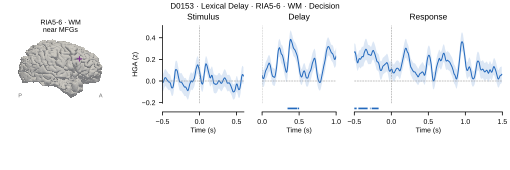

Decision figure: /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_d0153_ria56_decision/D0153_RIA5-6_LexicalDelay_Decision_spatiotemporal.svg
Validation: {'channels': ['D0153_RIA5-6'], 'conditions': ['Decision'], 'ylim': [-0.2054888308809184, 0.5132648989941274], 'brain_display_zoom': 1.0, 'bottom_legend': False, 'envelope_min': -0.173401610797211, 'envelope_max': 0.46834279087693703, 'significance_location': 'separate strip below waveform; no extra y-range', 'path': '/hpc/group/coganlab/nanlinshi/insula-functional/img/grant_d0153_ria56_decision/D0153_RIA5-6_LexicalDelay_Decision_spatiotemporal.svg', 'width_cm': 17.999999983333332, 'height_cm': 5.999999994444445, 'text_overlap_check': 'passed', 'text_clipping_check': 'passed', 'figure_sha256': '4b0a2fd5ddd2c20d30d7a52cc3af95de533a4014179aba54a128390360f2ded7', 'localization': 'Native virtual bipolar midpoint; WM, nearest gray matter MFGs; coordinates not snapped', 'windows': {'Stimulus': (-0.5, 0.6), 'Delay': (0, 1), 'Response'

In [2]:
ria_dec_path,ria_dec_validation=ria_dec.render(condition='Decision')
display(SVG(filename=str(ria_dec_path)))
print('Decision figure:',ria_dec_path)
print('Validation:',ria_dec_validation)
